In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Reading and opening our dataset


In [4]:
df = pd.read_csv("../data/raw/phishing_email.csv")
df.head()

,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


Checking our datasets dimensions

In [5]:
print("Rows: ", df.shape[0])
print("Columns: ", df.shape[1])

Rows:  82486
Columns:  2


Inspecting the columns and datatypes

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 82486 entries, 0 to 82485
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   text_combined  82486 non-null  str  
 1   label          82486 non-null  int64
dtypes: int64(1), str(1)
memory usage: 1.3 MB


Checking for missing values and duplicate rows


In [7]:
print(df.isnull().sum())
print("duplicates: " ,  df.duplicated().sum())

text_combined    0
label            0
dtype: int64
duplicates:  408


We will perform 3 more checks to determine:
1. Which number means phishing?
2. Are there any hidden duplicates that may look different but are basically the same email?
3. Is the subject line there so we can determine if wee should include it as a feature?

In [8]:
print(df['label'].value_counts())
print(df[df['label'] == 1]['text_combined'].head(3).tolist())
print("dup on text:", df.duplicated(subset=['text_combined']).sum())


label
1    42891
0    39595
Name: count, dtype: int64
['link dwl g 510 802 11 g wireless pci lan adapter 39 85 39 85 dwl g 510 high speed 2 4 ghz 802 11 g wireless pci lan adapter ieee 802 11 g standardupto 54 mbpsoperating frequency range 2 4 ghz ideal solution enabling wireless networking capabilities desktops pcs home office dwl g 510 visit http www computron com deals link dwl g 510 802 11 g wireless pci lan adapter link g 510 wireless pci adapter featuring latest ieee 802 11 g wireless technology deliverincredibly fast data transfer 2 4 ghz frequency g 510 features 802 11 g standard backwards compatible existing 802 11 11 b products already also offers 64 128 bit wep encryption includes removable antenna driver cd get link g 510 wireless pci lan adapter today general features pci interface removable antenna 64 128 bit wep encryption link act led plug play one stop distributorjebel ali duty free zonedubai uae www computron com latest clearance sale listing contact sales department 

### Initial Data Checks

1. **Which number means phishing?** 
   Based on the label distribution (`1` = 42,891 and `0` = 39,595) and inspecting the actual text, **1 = phishing** and **0 = legitimate**. The dataset is reasonably balanced.

2. **Are there any hidden duplicates?** 
   Yes. There are exactly **408 exact duplicate texts** in the dataset. This is about 0.5% of the data. We will need to drop these before training so they don't cause data leakage.

3. **Is the subject line there?** 
   No. The dataset only contains a single `text_combined` column which holds the raw email body. There is no separate subject column. We will drop subject-line features from our plan and rely on body text and structural features.

In [9]:
# 1. Drop the 408 exact duplicate emails
df_clean = df.drop_duplicates(subset=['text_combined']).copy()

# 2. Reset the index so row numbers are sequential
df_clean = df_clean.reset_index(drop=True)

# 3. Check the new shape
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("\nNew label counts:")
print(df_clean['label'].value_counts())

Original shape: (82486, 2)
Cleaned shape: (82078, 2)

New label counts:
label
1    42845
0    39233
Name: count, dtype: int64


In [ ]:
# 4. Save to the processed folder
#df_clean.to_csv("../data/processed/phishing_clean.csv", index=False)
print("Saved successfully!")

Saved successfully!


Since we do not have a subject line. The next thing we do is look at the data visually to figure out which feature to use.

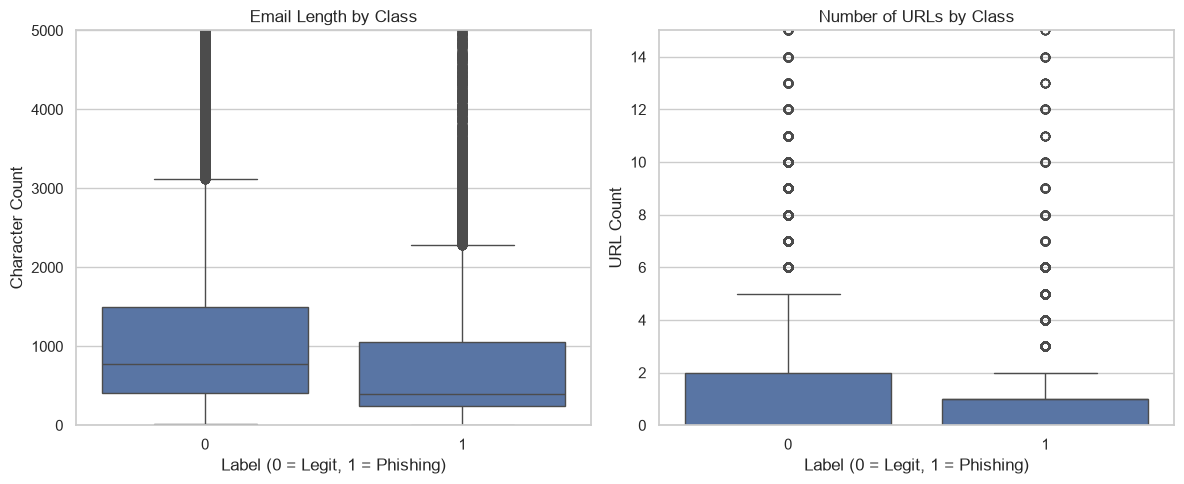

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Set a clean visual style
sns.set_theme(style = "whitegrid")

# Feature 1: Email character length
df_clean['char_length'] = df_clean['text_combined'].str.len()
plt.figure(figsize = (12,5))

# Char 1: Length
plt.subplot(1, 2, 1)
sns.boxplot(x='label', y='char_length', data=df_clean)
plt.title('Email Length by Class')
plt.xlabel('Label (0 = Legit, 1 = Phishing)')
plt.ylabel('Character Count')

# Limit y-axis so the chart isn't squished by massive outlier emails
plt.ylim(0, 5000) 


# Feature 2: Number of URLs
# Simple regex to find "http" or "www"
def count_urls(text):
    return len(re.findall(r'http|www', str(text)))

df_clean['url_count'] = df_clean['text_combined'].apply(count_urls)

# Chart 2: URLs
plt.subplot(1, 2, 2)
sns.boxplot(x='label', y='url_count', data=df_clean)
plt.title('Number of URLs by Class')
plt.xlabel('Label (0 = Legit, 1 = Phishing)')
plt.ylabel('URL Count')
plt.ylim(0, 15) # Limit y-axis to see the main distribution clearly

plt.tight_layout()
plt.show()


### Exploratory Data Analysis (EDA) Findings

Based on the initial charts comparing legitimate (0) and phishing (1) emails:

1. **Email Length:** Phishing emails are generally **much shorter** than legitimate emails. The median length for phishing is around 350 characters, compared to roughly 750 characters for legitimate emails. Legitimate emails (like corporate Enron emails) often contain long threads and signatures, while phishing emails tend to be short and punchy.
2. **URL Count:** While both classes contain URLs, their distribution differs. The median URL count for legitimate emails is around 1. Phishing emails have a lower median but a much longer "tail" of outliers, with some containing 10 to 15+ URLs. 

**Takeaway for Feature Engineering:** 
Email character length and URL count are highly predictive features. We will combine these structural features with the actual words used in the text (TF-IDF) to train our model. 